In [ ]:
import gymnasium as gym
import torch
import torch.nn as nn
import numpy as np


# Red DQN simple - misma arquitectura que usamos en S7
class DQN(nn.Module):
    def __init__(self, state_dim=4, n_actions=2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, n_actions),
        )

    def forward(self, x):
        return self.net(x)


# Cargar pesos pre-entrenados (archivo generado en el lab 7 )
expert_dqn = DQN()
expert_dqn.load_state_dict(torch.load("experto_cartpole.pth"))
expert_dqn.eval()

DQN(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
)

In [ ]:
def expert_policy(obs):
    """Agente DQN experto: elige la accion con Q mas alto."""
    with torch.no_grad():
        obs_t = torch.FloatTensor(obs).unsqueeze(0)
        q_vals = expert_dqn(obs_t)
        return q_vals.argmax().item()  # accion greedy


def collect_demos(env, n_episodes=50):
    demos = []  # lista de (obs, action)
    for ep in range(n_episodes):
        obs, _ = env.reset(seed=ep)
        while True:
            action = expert_policy(obs)  # experto decide
            demos.append((obs.copy(), action))  # guardar par
            obs, _, done, trunc, _ = env.step(action)
            if done or trunc:
                break
    return demos  # [(obs_0,a_0), (obs_1,a_1), ...]


env = gym.make("CartPole-v1")
demos = collect_demos(env, n_episodes=50)
print(f"Total pares: {len(demos)}")  # ~25,000 pares
print(f"Obs shape: {demos[0][0].shape}")  # (4,)

Total pares: 25000
Obs shape: (4,)


In [ ]:
class BCPolicy(nn.Module):
    def __init__(self, state_dim=4, n_actions=2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, n_actions),
        )  # output = logits (sin softmax)

    def forward(self, x):
        return self.net(x)  # logits

    def predict(self, obs):
        with torch.no_grad():
            obs_t = torch.FloatTensor(obs).unsqueeze(0)
            return self.forward(obs_t).argmax().item()

In [ ]:
# Preparar tensores desde la lista de demos
states = torch.FloatTensor([d[0] for d in demos])
actions = torch.LongTensor([d[1] for d in demos])

# Modelo, optimizador y loss
bc_policy = BCPolicy(state_dim=4, n_actions=2)
optimizer = torch.optim.Adam(bc_policy.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss()

train_losses = []
N_EPOCHS = 50

for epoch in range(N_EPOCHS):
    bc_policy.train()
    logits = bc_policy(states)  # forward pass
    loss = loss_fn(logits, actions)  # CE loss
    optimizer.zero_grad()  # limpiar gradientes
    loss.backward()  # backward pass
    optimizer.step()  # actualizar pesos
    train_losses.append(loss.item())
    if epoch % 10 == 0:
        print(f"Epoch {epoch:3d}: loss = {loss.item():.4f}")

/var/folders/b4/lfyym6_9229g76m1knppz8nw0000gn/T/ipykernel_10699/3875131214.py:2: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:252.)
  states  = torch.FloatTensor([d[0] for d in demos])


Epoch   0: loss = 0.6959
Epoch  10: loss = 0.6210
Epoch  20: loss = 0.5386
Epoch  30: loss = 0.4559
Epoch  40: loss = 0.4019


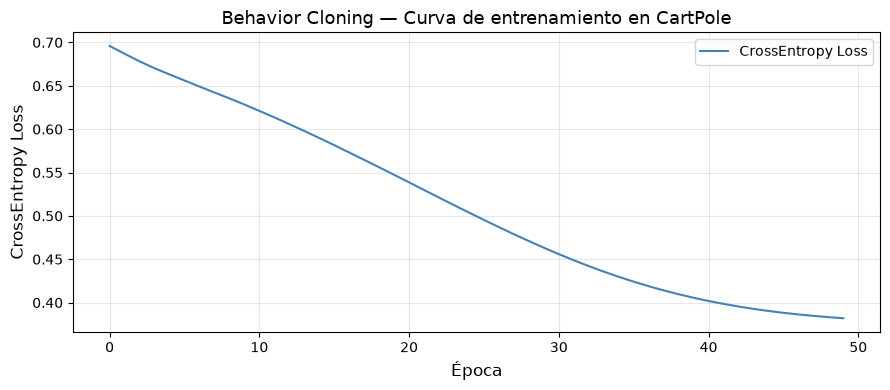

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 4))
plt.plot(train_losses, color="steelblue", linewidth=1.5, label="CrossEntropy Loss")
plt.xlabel("Época", fontsize=12)
plt.ylabel("CrossEntropy Loss", fontsize=12)
plt.title("Behavior Cloning — Curva de entrenamiento en CartPole", fontsize=13)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
def evaluate_policy(policy_fn, env, n_episodes=50):
    rewards = []
    for ep in range(n_episodes):
        obs, _ = env.reset(seed=1000 + ep)  # seeds distintos al training
        total, done = 0, False
        while not done:
            action = policy_fn(obs)
            obs, r, done, trunc, _ = env.step(action)
            total += r
            done = done or trunc
        rewards.append(total)
    return rewards


env = gym.make("CartPole-v1")
r_expert = evaluate_policy(expert_policy, env)
r_bc = evaluate_policy(bc_policy.predict, env)

print(f"Experto — promedio: {np.mean(r_expert):.1f}  std: {np.std(r_expert):.1f}")
print(f"BC      — promedio: {np.mean(r_bc):.1f}  std: {np.std(r_bc):.1f}")

Experto — promedio: 500.0  std: 0.0
BC      — promedio: 83.9  std: 29.4


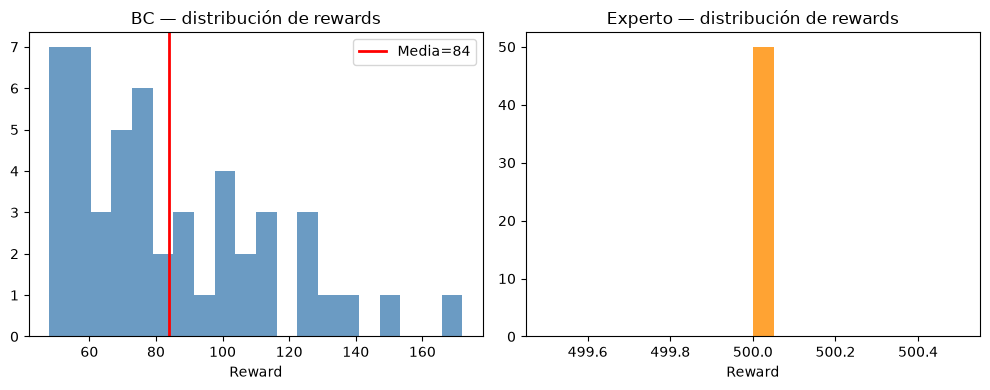

In [ ]:
# Ver la distribución de longitudes de episodio
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.hist(r_bc, bins=20, color="steelblue", alpha=0.8)
plt.axvline(np.mean(r_bc), color="red", lw=2, label=f"Media={np.mean(r_bc):.0f}")
plt.xlabel("Reward")
plt.title("BC — distribución de rewards")
plt.legend()
plt.subplot(1, 2, 2)
plt.hist(r_expert, bins=20, color="darkorange", alpha=0.8)
plt.xlabel("Reward")
plt.title("Experto — distribución de rewards")
plt.tight_layout()
plt.show()

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Panel izq: curvas de reward
ax = axes[0]
ax.plot(r_bc, "o-", color="steelblue", lw=1.5, ms=3, label="BC")
ax.plot(r_expert, "s-", color="darkorange", lw=1.5, ms=3, label="Experto DQN")
ax.axhline(np.mean(r_bc), color="steelblue", ls="--", alpha=0.6)
ax.set_xlabel("Episodio")
ax.set_ylabel("Reward")
ax.legend()
ax.grid(alpha=0.3)

# Panel der: boxplot
axes[1].boxplot(
    [r_bc, r_expert],
    labels=["BC", "Experto"],
    patch_artist=True,
    boxprops=dict(facecolor="lightblue"),
)
axes[1].set_ylabel("Reward")
axes[1].set_title("Distribución rewards")
plt.suptitle("BC vs. Experto en CartPole-v1", fontsize=14)
plt.tight_layout()
plt.show()

NameError: name 'plt' is not defined